In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

df = pd.read_csv("est_matchs.csv", parse_dates=["date"])
print(df.shape)
df.head(10)

(57, 11)


,saison,date,competition,tour,adversaire,lieu,buts_est,buts_adversaire,resultat,buteurs_est,notes
0,2025-26,2025-08-03,Supercoupe de Tunisie,Finale,Stade Tunisien,neutre,1,0,V,Belaïli (pen),Vainqueur de la Supercoupe
1,2025-26,2025-08-09,Ligue 1,J1,AS Gabès,extérieur,0,0,N,NaN,NaN
2,2025-26,2025-08-15,Ligue 1,J2,US Monastir,domicile,1,1,N,NaN,NaN
3,2025-26,2025-08-21,Ligue 1,J3,JS Kairouan,extérieur,4,0,V,NaN,NaN
4,2025-26,2025-08-28,Ligue 1,J4,AS Soliman,domicile,2,0,V,NaN,NaN
5,2025-26,2025-09-13,Ligue 1,J5,Stade Tunisien,extérieur,0,1,D,NaN,NaN
6,2025-26,2025-09-16,Ligue 1,J6,ES Métlaoui,domicile,2,0,V,NaN,NaN
7,2025-26,2025-09-21,Ligue des champions CAF,Tour préliminaire 1 - aller,AS FAN (Niger),extérieur,3,0,V,Boualia; Diakité; Diakité,NaN
8,2025-26,2025-09-24,Ligue 1,J7,Olympique Béja,domicile,2,0,V,NaN,NaN
9,2025-26,2025-09-27,Ligue des champions CAF,Tour préliminaire 1 - retour,AS FAN (Niger),domicile,4,1,V,Belaïli; Sasse; Keita; Meriah (pen),Qualifié 7-1 cumulé


In [2]:
df["diff"] = df["buts_est"] - df["buts_adversaire"]
df["points"] = np.select([df.resultat == "V", df.resultat == "N"], [3, 1], default=0)
df["clean_sheet"] = df["buts_adversaire"] == 0
df["a_marque"] = df["buts_est"] > 0
df["total_buts"] = df["buts_est"] + df["buts_adversaire"]
df[["date", "competition", "adversaire", "lieu", "buts_est", "buts_adversaire", "resultat", "diff", "points"]].tail(8)

,date,competition,adversaire,lieu,buts_est,buts_adversaire,resultat,diff,points
49,2026-05-31,Coupe de Tunisie,ES Zarzis,neutre,1,0,V,1,3
50,2026-08-23,Ligue 1,Étoile du Sahel,domicile,3,2,V,1,3
51,2026-08-30,Ligue 1,JS El Omrane,extérieur,1,3,D,-2,0
52,2026-09-06,Ligue 1,AS Marsa,domicile,2,1,V,1,3
53,2026-09-13,Ligue 1,CS Hammam-Lif,extérieur,1,0,V,1,3
54,2026-10-10,Ligue 1,Olympique Béja,domicile,3,1,V,2,3
55,2026-10-18,Ligue des champions CAF,Asswehly SC (Libye),extérieur,0,1,D,-1,0
56,2026-10-24,Ligue des champions CAF,Asswehly SC (Libye),domicile,1,0,V,1,3


In [3]:
def bilan(g):
    return pd.Series({
        "Matchs": len(g),
        "V": (g.resultat == "V").sum(),
        "N": (g.resultat == "N").sum(),
        "D": (g.resultat == "D").sum(),
        "Buts marqués": g.buts_est.sum(),
        "Buts encaissés": g.buts_adversaire.sum(),
        "Différence": g["diff"].sum(),
        "% victoires": round(100 * (g.resultat == "V").mean(), 1),
        "Moy. buts marqués": round(g.buts_est.mean(), 2),
        "Moy. buts encaissés": round(g.buts_adversaire.mean(), 2),
        "Clean sheets": g.clean_sheet.sum(),
    }, dtype=object)

bilan_saison = df.groupby("saison").apply(bilan, include_groups=False)
bilan_saison

,Matchs,V,N,D,Buts marqués,Buts encaissés,Différence,% victoires,Moy. buts marqués,Moy. buts encaissés,Clean sheets
saison,,,,,,,,,,,
2025-26,50,32,12,6,80,21,59,64.0,1.60,0.42,33
2026-27,7,5,0,2,11,8,3,71.4,1.57,1.14,2


In [4]:
s25 = df[df.saison == "2025-26"]
bilan_comp = s25.groupby("competition").apply(bilan, include_groups=False)
bilan_comp

,Matchs,V,N,D,Buts marqués,Buts encaissés,Différence,% victoires,Moy. buts marqués,Moy. buts encaissés,Clean sheets
competition,,,,,,,,,,,
Coupe de Tunisie,5,5,0,0,13,1,12,100.0,2.6,0.20,4
Ligue 1,30,18,9,3,45,11,34,60.0,1.5,0.37,21
Ligue des champions CAF,14,8,3,3,21,9,12,57.1,1.5,0.64,7
Supercoupe de Tunisie,1,1,0,0,1,0,1,100.0,1.0,0.00,1


In [5]:
l25 = s25[s25.competition == "Ligue 1"].copy()
print("Points :", l25.points.sum())
print("Buts marqués / encaissés :", l25.buts_est.sum(), "/", l25.buts_adversaire.sum())

# Domicile vs extérieur
dom_ext = l25.groupby("lieu").apply(bilan, include_groups=False)
dom_ext

Points : 63
Buts marqués / encaissés : 45 / 11


,Matchs,V,N,D,Buts marqués,Buts encaissés,Différence,% victoires,Moy. buts marqués,Moy. buts encaissés,Clean sheets
lieu,,,,,,,,,,,
domicile,15,11,3,1,25,5,20,73.3,1.67,0.33,11
extérieur,15,7,6,2,20,6,14,46.7,1.33,0.40,10


In [6]:
# Points cumulés au fil des journées + rang de rythme
l25["points_cumules"] = l25.points.cumsum()
l25["buts_marques_cumules"] = l25.buts_est.cumsum()
l25[["tour", "date", "adversaire", "buts_est", "buts_adversaire", "resultat", "points_cumules"]].tail(10)

,tour,date,adversaire,buts_est,buts_adversaire,resultat,points_cumules
31,J21,2026-02-25,ES Métlaoui,1,1,N,47
32,J22,2026-03-01,Olympique Béja,3,0,V,50
33,J23,2026-03-07,AS Marsa,1,0,V,53
37,J24,2026-04-04,Étoile du Sahel,0,0,N,54
40,J25,2026-04-23,ES Zarzis,2,2,N,55
41,J26,2026-04-26,CA Bizertin,1,1,N,56
42,J27,2026-04-30,CS Sfaxien,0,0,N,57
43,J28,2026-05-04,JS El Omrane,1,0,V,60
44,J29,2026-05-10,Club Africain,0,1,D,60
45,J30,2026-05-14,US Ben Guerdane,1,0,V,63


In [7]:
def plus_longue_serie(mask):
    mask = np.asarray(mask, dtype=int)
    best = cur = 0
    for m in mask:
        cur = cur + 1 if m else 0
        best = max(best, cur)
    return best

print("Plus longue série sans défaite (Ligue 1 2025-26) :", plus_longue_serie(l25.resultat != "D"))
print("Plus longue série de victoires (Ligue 1 2025-26)  :", plus_longue_serie(l25.resultat == "V"))
print("Plus longue série sans encaisser (Ligue 1 2025-26):", plus_longue_serie(l25.clean_sheet))
print("Plus longue série sans défaite (tous matchs 2025-26):", plus_longue_serie(s25.resultat != "D"))

Plus longue série sans défaite (Ligue 1 2025-26) : 11
Plus longue série de victoires (Ligue 1 2025-26)  : 4
Plus longue série sans encaisser (Ligue 1 2025-26): 6
Plus longue série sans défaite (tous matchs 2025-26): 17


In [8]:
h2h = (l25.groupby("adversaire")
          .agg(matchs=("date", "count"), points=("points", "sum"),
               bp=("buts_est", "sum"), bc=("buts_adversaire", "sum"))
          .assign(diff=lambda x: x.bp - x.bc)
          .sort_values(["points", "diff"], ascending=False))
h2h

,matchs,points,bp,bc,diff
adversaire,,,,,
AS Soliman,2,6,5,0,5
JS El Omrane,2,6,5,0,5
JS Kairouan,2,6,5,0,5
Olympique Béja,2,6,5,0,5
US Ben Guerdane,2,6,5,0,5
AS Marsa,2,6,4,0,4
CA Bizertin,2,4,3,1,2
ES Métlaoui,2,4,3,1,2
AS Gabès,2,4,2,1,1


In [9]:
print("Adversaires qui ont pris des points à l'EST (défaite ou nul) :")
print(l25[l25.resultat != "V"][["date", "adversaire", "lieu", "buts_est", "buts_adversaire", "resultat"]].to_string(index=False))

Adversaires qui ont pris des points à l'EST (défaite ou nul) :
      date      adversaire      lieu  buts_est  buts_adversaire resultat
2025-08-09        AS Gabès extérieur         0                0        N
2025-08-15     US Monastir  domicile         1                1        N
2025-09-13  Stade Tunisien extérieur         0                1        D
2025-10-22       ES Zarzis extérieur         0                0        N
2025-11-09   Club Africain extérieur         0                0        N
2026-01-19     US Monastir extérieur         1                2        D
2026-02-25     ES Métlaoui extérieur         1                1        N
2026-04-04 Étoile du Sahel extérieur         0                0        N
2026-04-23       ES Zarzis  domicile         2                2        N
2026-04-26     CA Bizertin extérieur         1                1        N
2026-04-30      CS Sfaxien  domicile         0                0        N
2026-05-10   Club Africain  domicile         0               

In [10]:
print("Plus larges victoires :")
print(df.nlargest(5, "diff")[["date", "competition", "adversaire", "buts_est", "buts_adversaire"]].to_string(index=False))
print()
print("Défaites :")
print(df[df.resultat == "D"][["date", "competition", "adversaire", "lieu", "buts_est", "buts_adversaire"]].to_string(index=False))
print()
print("Matchs les plus prolifiques :")
print(df.nlargest(5, "total_buts")[["date", "competition", "adversaire", "buts_est", "buts_adversaire"]].to_string(index=False))

Plus larges victoires :
      date             competition      adversaire  buts_est  buts_adversaire
2026-03-28        Coupe de Tunisie     WS El Hamma         5                0
2025-08-21                 Ligue 1     JS Kairouan         4                0
2025-11-06                 Ligue 1    JS El Omrane         4                0
2026-01-10                 Ligue 1 US Ben Guerdane         4                0
2025-09-21 Ligue des champions CAF  AS FAN (Niger)         3                0

Défaites :
      date             competition                         adversaire      lieu  buts_est  buts_adversaire
2025-09-13                 Ligue 1                     Stade Tunisien extérieur         0                1
2026-01-19                 Ligue 1                        US Monastir extérieur         1                2
2026-02-08 Ligue des champions CAF                Stade Malien (Mali) extérieur         0                1
2026-04-12 Ligue des champions CAF Mamelodi Sundowns (Afrique du Sud

In [11]:
cl = s25[s25.competition == "Ligue des champions CAF"]
parcours = cl.groupby(cl.tour.str.replace(r" - (aller|retour)$", "", regex=True), sort=False).apply(bilan, include_groups=False)
parcours[["Matchs", "V", "N", "D", "Buts marqués", "Buts encaissés"]]

,Matchs,V,N,D,Buts marqués,Buts encaissés
tour,,,,,,
Tour préliminaire 1,2,2,0,0,7,1
Tour préliminaire 2,2,2,0,0,4,0
Phase de groupes J1,1,0,1,0,0,0
Phase de groupes J2,1,0,1,0,1,1
Phase de groupes J3,1,1,0,0,1,0
Phase de groupes J4,1,0,1,0,2,2
Phase de groupes J5,1,0,0,1,0,1
Phase de groupes J6,1,1,0,0,2,0
Quart de finale,2,2,0,0,4,2


In [12]:
b = df.dropna(subset=["buteurs_est"]).copy()
b["buteur"] = b.buteurs_est.str.split(";")
b = b.explode("buteur")
b["buteur"] = b.buteur.str.replace(r"\s*\(pen\)", "", regex=True).str.strip()
b.groupby("buteur").size().sort_values(ascending=False).rename("buts (matchs renseignés)").to_frame()

,buts (matchs renseignés)
buteur,
Belaïli,4
Danho,4
Jelassi,4
Sasse,3
Diakité,3
Hadj Ali,2
Boualia,2
Ben Ali,1
Ben Hamida,1


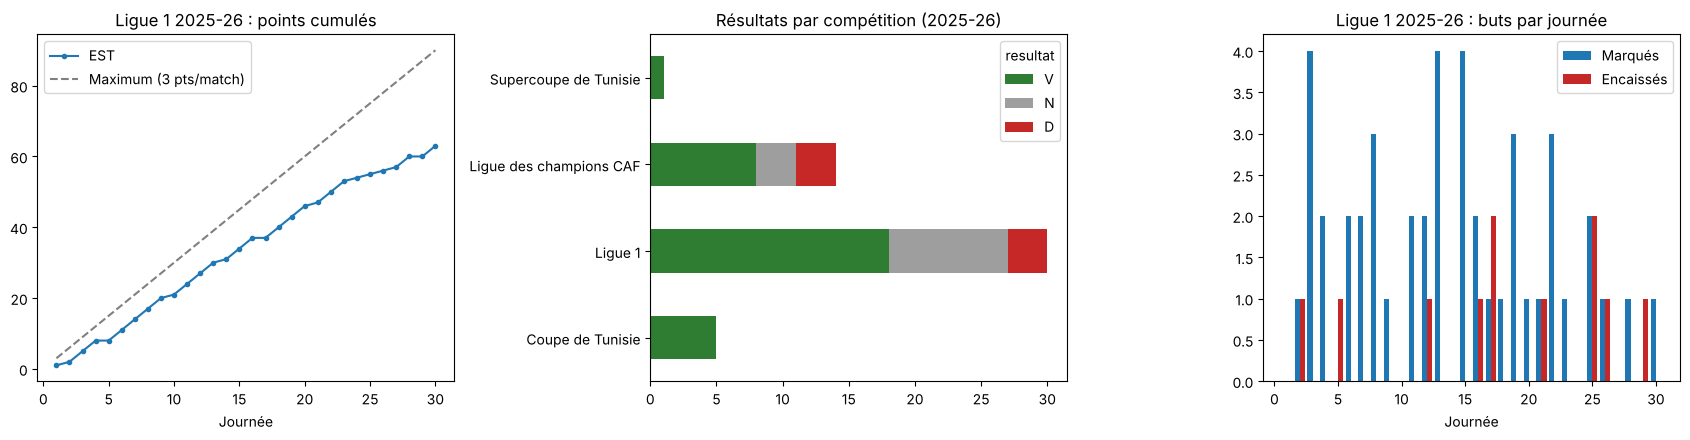

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) Points cumulés Ligue 1 vs rythme idéal
x = np.arange(1, len(l25) + 1)
axes[0].plot(x, l25.points_cumules.values, marker="o", ms=3, label="EST")
axes[0].plot(x, 3 * x, ls="--", color="gray", label="Maximum (3 pts/match)")
axes[0].set_title("Ligue 1 2025-26 : points cumulés")
axes[0].set_xlabel("Journée"); axes[0].legend()

# (b) Résultats par compétition
res = s25.pivot_table(index="competition", columns="resultat", values="date", aggfunc="count", fill_value=0)
res = res.reindex(columns=["V", "N", "D"], fill_value=0)
res.plot(kind="barh", stacked=True, ax=axes[1], color=["#2e7d32", "#9e9e9e", "#c62828"])
axes[1].set_title("Résultats par compétition (2025-26)"); axes[1].set_ylabel("")

# (c) Buts marqués / encaissés par journée de Ligue 1
w = 0.4
axes[2].bar(x - w/2, l25.buts_est, w, label="Marqués")
axes[2].bar(x + w/2, l25.buts_adversaire, w, label="Encaissés", color="#c62828")
axes[2].set_title("Ligue 1 2025-26 : buts par journée")
axes[2].set_xlabel("Journée"); axes[2].legend()

plt.tight_layout()
plt.show()

In [14]:
s26 = df[df.saison == "2026-27"]
print(s26[["date", "competition", "tour", "adversaire", "lieu", "buts_est", "buts_adversaire", "resultat", "notes"]].to_string(index=False))
l26 = s26[s26.competition == "Ligue 1"]
print()
print(f"Ligue 1 2026-27 : {len(l26)} matchs, {l26.points.sum()} points, {l26.buts_est.sum()}-{l26.buts_adversaire.sum()}")

      date             competition                         tour          adversaire      lieu  buts_est  buts_adversaire resultat                                    notes
2026-08-23                 Ligue 1                           J1     Étoile du Sahel  domicile         3                2        V                                      NaN
2026-08-30                 Ligue 1                           J2        JS El Omrane extérieur         1                3        D                                      NaN
2026-09-06                 Ligue 1                           J3            AS Marsa  domicile         2                1        V                                      NaN
2026-09-13                 Ligue 1                           J4       CS Hammam-Lif extérieur         1                0        V                                      NaN
2026-10-10                 Ligue 1                           J5      Olympique Béja  domicile         3                1        V                